In [1]:
%%writefile numcheck.py
import random
import re
from dataclasses import dataclass

UNITS = {
    "%": "%", "ev": "eV", "mev": "meV", "v": "V", "mv": "mV",
    "ma/cm2": "mA/cm2", "ma cm-2": "mA/cm2", "ma/cm²": "mA/cm2",
    "nm": "nm", "um": "um", "μm": "um", "µm": "um", "k": "K", "°c": "C",
    "ns": "ns", "us": "us", "μs": "us", "µs": "us",
    "w/m2": "W/m2", "w/m²": "W/m2", "ghz": "GHz", "mpa": "MPa", "gpa": "GPa",
}

KEYWORDS = [
    "efficiency", "bandgap", "band gap", "voltage", "current", "resistance",
    "thickness", "temperature", "lifetime", "advantage", "gain", "fill factor",
    "stability", "retention", "strength", "conductivity", "mobility",
    "loss", "limit", "capacity", "yield", "accuracy",
]

NUM = r"(?P<num>\d+(?:\.\d+)?)"
UNIT_ALT = "|".join(sorted((re.escape(u) for u in UNITS), key=len, reverse=True))
QTY_RE = re.compile(NUM + r"\s*(?P<unit>" + UNIT_ALT + r")(?![A-Za-z])", re.IGNORECASE)


@dataclass
class Qty:
    value: float
    unit: str
    keyword: str
    decimals: int
    start: int
    end: int
    raw: str


def _decimals(num_str):
    return len(num_str.split(".")[1]) if "." in num_str else 0


def extract_quantities(text, window=80):
    out = []
    low = text.lower()
    for m in QTY_RE.finditer(text):
        unit = UNITS[m.group("unit").lower()]
        s = m.start()
        ctx = low[max(0, s - window): s]
        kw, best = "", -1
        for k in KEYWORDS:
            i = ctx.rfind(k)
            if i > best:
                kw, best = k, i
        kw = kw.replace("band gap", "bandgap")
        num = m.group("num")
        out.append(Qty(float(num), unit, kw, _decimals(num), m.start(), m.end(), m.group(0)))
    return out


def values_match(a, b):
    tol = max(0.5 * 10 ** (-a.decimals), 0.003 * abs(b.value))
    return abs(a.value - b.value) <= tol + 1e-9


def check(abstract, body):
    a_qs = extract_quantities(abstract)
    b_qs = extract_quantities(body)
    flags = []
    for a in a_qs:
        same_unit = [b for b in b_qs if b.unit == a.unit]
        if any(values_match(a, b) for b in same_unit):
            continue
        same_kw = [b for b in same_unit if a.keyword and b.keyword == a.keyword]
        if same_kw:
            flags.append({
                "raw": a.raw, "keyword": a.keyword, "unit": a.unit,
                "abstract_value": a.value, "start": a.start,
                "body_values": sorted({b.value for b in same_kw})[:8],
                "reason": "abstract value not found; body has different values for the same quantity",
            })
    return flags


def perturb(value, decimals, rng):
    factor = rng.choice([0.6, 0.75, 1.25, 1.4, 1.6])
    new = round(value * factor, decimals)
    if new == value:
        new = round(value + 1, decimals)
    return new


def inject_error(abstract, body, idx, rng):
    a_qs = extract_quantities(abstract)
    q = a_qs[idx]
    b_vals = [b for b in extract_quantities(body) if b.unit == q.unit]
    for _ in range(20):
        new_val = perturb(q.value, q.decimals, rng)
        fake = Qty(new_val, q.unit, q.keyword, q.decimals, 0, 0, "")
        if not any(values_match(fake, b) for b in b_vals):
            break
    new_num = f"{new_val:.{q.decimals}f}"
    old_num = re.match(NUM, q.raw).group("num")
    new_raw = new_num + q.raw[len(old_num):]
    new_abs = abstract[:q.start] + new_raw + abstract[q.end:]
    return new_abs, {"old": q.raw, "new": new_raw, "keyword": q.keyword}


def checkable_indices(abstract, body):
    a_qs = extract_quantities(abstract)
    b_qs = extract_quantities(body)
    idxs = []
    for i, a in enumerate(a_qs):
        same_unit = [b for b in b_qs if b.unit == a.unit]
        same_kw = [b for b in same_unit if a.keyword and b.keyword == a.keyword]
        if same_kw and any(values_match(a, b) for b in same_unit):
            idxs.append(i)
    return idxs


def evaluate(papers, trials_per_paper=5, seed=0):
    rng = random.Random(seed)
    rows, tp, fn, fp = [], 0, 0, 0
    for pid, (abstract, body) in papers.items():
        fp += len(check(abstract, body))
        idxs = checkable_indices(abstract, body)
        for idx in rng.sample(idxs, min(trials_per_paper, len(idxs))):
            bad_abs, info = inject_error(abstract, body, idx, rng)
            flags = check(bad_abs, body)
            hit = any(f["raw"] == info["new"] for f in flags)
            tp += hit
            fn += (not hit)
            rows.append({"paper": pid, **info, "detected": hit})
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"tp": tp, "fn": fn, "clean_flags": fp, "precision": precision,
            "recall": recall, "f1": f1}, rows


def load_arxiv(arxiv_id):
    import requests, fitz
    r = requests.get(f"https://arxiv.org/pdf/{arxiv_id}", timeout=60)
    r.raise_for_status()
    doc = fitz.open(stream=r.content, filetype="pdf")
    text = "\n".join(p.get_text() for p in doc)
    return split_abstract(text)


def split_abstract(text):
    m = re.search(r"\bintroduction\b", text, re.IGNORECASE)
    cut = m.start() if m and m.start() > 300 else min(2500, len(text) // 8)
    return text[:cut], text[cut:]

Writing numcheck.py


In [2]:
!pip install requests pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 47.3 MB/s eta 0:00:00


In [3]:
from numcheck import load_arxiv, evaluate
ids = ["1706.08610","1801.02941","1506.01039","2106.03881","1910.07422","1810.01333"]
papers = {i: load_arxiv(i) for i in ids}
metrics, rows = evaluate(papers, trials_per_paper=5)
print(metrics)
for r in rows: print(r)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


{'tp': 11, 'fn': 0, 'clean_flags': 3, 'precision': 0.7857142857142857, 'recall': 1.0, 'f1': 0.88}
{'paper': '1706.08610', 'old': '14%', 'new': '8%', 'keyword': 'advantage', 'detected': True}
{'paper': '1801.02941', 'old': '31%', 'new': '39%', 'keyword': 'loss', 'detected': True}
{'paper': '1801.02941', 'old': '40%', 'new': '56%', 'keyword': 'loss', 'detected': True}
{'paper': '1801.02941', 'old': '25%', 'new': '19%', 'keyword': 'loss', 'detected': True}
{'paper': '1506.01039', 'old': '25%', 'new': '31%', 'keyword': 'efficiency', 'detected': True}
{'paper': '2106.03881', 'old': '21%', 'new': '13%', 'keyword': 'limit', 'detected': True}
{'paper': '1910.07422', 'old': '31%', 'new': '39%', 'keyword': 'efficiency', 'detected': True}
{'paper': '1910.07422', 'old': '1.5 eV', 'new': '2.1 eV', 'keyword': 'bandgap', 'detected': True}
{'paper': '1910.07422', 'old': '10 µs', 'new': '16 µs', 'keyword': 'lifetime', 'detected': True}
{'paper': '1910.07422', 'old': '95%', 'new': '57%', 'keyword': 'ban

In [4]:
from numcheck import check
for pid, (abs_, body) in papers.items():
    for f in check(abs_, body):
        print(pid, "|", f["raw"], "|", f["keyword"], "| body has:", f["body_values"])

1801.02941 | 19% | efficiency | body has: [22.0]
1801.02941 | 35% | loss | body has: [6.0, 15.0, 25.0, 40.0]
1801.02941 | 35% | loss | body has: [6.0, 15.0, 25.0, 40.0]


In [5]:
import random, numcheck
def small_perturb(value, decimals, rng):
    new = round(value * rng.choice([0.9, 0.95, 1.05, 1.1]), decimals)
    return new if new != value else round(value + 1, decimals)
numcheck.perturb = small_perturb
m, r = numcheck.evaluate(papers, trials_per_paper=5)
print(m)

{'tp': 10, 'fn': 1, 'clean_flags': 3, 'precision': 0.7692307692307693, 'recall': 0.9090909090909091, 'f1': 0.8333333333333333}


Big errors:   240/240 caught, recall 1.00
Small errors: 200/240 caught, recall 0.83

Missed (small errors):
('1910.07422', '1.4 eV', '1.3 eV') bandgap
('1910.07422', '1.5 eV', '1.7 eV') bandgap
('1910.07422', '1.4 eV', '1.5 eV') bandgap
('1910.07422', '1.5 eV', '1.4 eV') bandgap
('1910.07422', '1.5 eV', '1.6 eV') bandgap


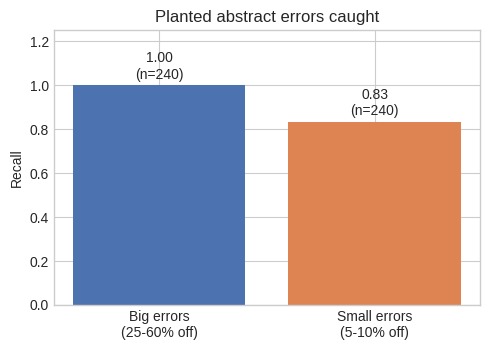

In [6]:
import numcheck
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

def large_perturb(value, decimals, rng):
    new = round(value * rng.choice([0.6, 0.75, 1.25, 1.4, 1.6]), decimals)
    return new if new != value else round(value + 1, decimals)

def small_perturb(value, decimals, rng):
    new = round(value * rng.choice([0.9, 0.95, 1.05, 1.1]), decimals)
    return new if new != value else round(value + 1, decimals)

def run(perturb_fn, seeds=20):
    numcheck.perturb = perturb_fn
    tp = fn = 0
    missed = {}
    for s in range(seeds):
        m, rows = numcheck.evaluate(papers, trials_per_paper=50, seed=s)
        tp += m["tp"]
        fn += m["fn"]
        for r in rows:
            if not r["detected"]:
                missed[(r["paper"], r["old"], r["new"])] = r["keyword"]
    return tp, fn, missed

tp_b, fn_b, miss_b = run(large_perturb)
tp_s, fn_s, miss_s = run(small_perturb)
rec_b = tp_b / (tp_b + fn_b)
rec_s = tp_s / (tp_s + fn_s)
print(f"Big errors:   {tp_b}/{tp_b+fn_b} caught, recall {rec_b:.2f}")
print(f"Small errors: {tp_s}/{tp_s+fn_s} caught, recall {rec_s:.2f}")
print("\nMissed (small errors):")
for k, v in miss_s.items():
    print(k, v)

fig, ax = plt.subplots(figsize=(5, 3.6))
labels = ["Big errors\n(25-60% off)", "Small errors\n(5-10% off)"]
vals = [rec_b, rec_s]
ns = [tp_b + fn_b, tp_s + fn_s]
ax.bar(labels, vals, color=["#4C72B0", "#DD8452"])
for i, (v, n) in enumerate(zip(vals, ns)):
    ax.text(i, v + 0.03, f"{v:.2f}\n(n={n})", ha="center")
ax.set_ylim(0, 1.25)
ax.set_ylabel("Recall")
ax.set_title("Planted abstract errors caught")
plt.tight_layout()
plt.savefig("results.png", dpi=200)
plt.show()

In [7]:
import numcheck
for pid, (a, b) in papers.items():
    print(pid, "| checkable numbers:", len(numcheck.checkable_indices(a, b)),
          "| clean flags:", len(numcheck.check(a, b)))
a, b = papers["1910.07422"]
print("bandgap values in 1910.07422 body:",
      sorted({q.value for q in numcheck.extract_quantities(b) if q.unit == "eV" and q.keyword == "bandgap"}))

1706.08610 | checkable numbers: 1 | clean flags: 0
1801.02941 | checkable numbers: 3 | clean flags: 3
1506.01039 | checkable numbers: 1 | clean flags: 0
2106.03881 | checkable numbers: 1 | clean flags: 0
1910.07422 | checkable numbers: 6 | clean flags: 0
1810.01333 | checkable numbers: 0 | clean flags: 0
bandgap values in 1910.07422 body: [1.34, 1.36, 1.4, 1.5, 1.6, 1.63, 1.7, 1.8, 2.0, 2.4, 3.0, 3.3, 3.5, 3.6]


In [9]:
import re, time, urllib.request, urllib.parse
import xml.etree.ElementTree as ET
import numcheck

HDR = {"User-Agent": "numcheck-hackathon/0.1 (student project)"}

def http_get(url, tries=4):
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers=HDR)
            return urllib.request.urlopen(req, timeout=60).read()
        except Exception as e:
            wait = 20 * (k + 1)
            print(f"retry {k+1}/{tries} after error: {e} (waiting {wait}s)")
            time.sleep(wait)
    return None

def good_abstract(text):
    return len([q for q in numcheck.extract_quantities(text) if q.keyword]) >= 2

def candidates_from_api(n=80):
    q = "cat:cond-mat.mtrl-sci AND (abs:efficiency OR abs:bandgap)"
    url = ("https://export.arxiv.org/api/query?search_query=" + urllib.parse.quote(q)
           + f"&sortBy=submittedDate&sortOrder=descending&max_results={n}")
    data = http_get(url)
    if data is None:
        return None
    ns = {"a": "http://www.w3.org/2005/Atom"}
    out = []
    for e in ET.fromstring(data).findall("a:entry", ns):
        aid = re.sub(r"v\d+$", "", e.find("a:id", ns).text.split("/abs/")[-1])
        out.append(aid)
    return out

def candidates_from_list():
    html = http_get("https://arxiv.org/list/cond-mat.mtrl-sci/recent?skip=0&show=100")
    if html is None:
        return []
    ids = re.findall(r"/abs/(\d{4}\.\d{4,5})", html.decode("utf-8", "ignore"))
    return list(dict.fromkeys(ids))

cands = candidates_from_api()
if cands is None:
    print("API blocked, using the recent-papers list instead")
    cands = candidates_from_list()
print("candidates:", len(cands))

picked, attempts = [], 0
for aid in cands:
    if aid in papers:
        continue
    if len(picked) == 10 or attempts == 40:
        break
    attempts += 1
    try:
        a, b = numcheck.load_arxiv(aid)
    except Exception as e:
        print("load failed:", aid, e)
        continue
    time.sleep(3)
    if good_abstract(a):
        papers[aid] = (a, b)
        picked.append(aid)
print("Picked:", picked)

total = 0
for pid, (a, b) in papers.items():
    n = len(numcheck.checkable_indices(a, b))
    total += n
    print(pid, "| checkable:", n, "| clean flags:", len(numcheck.check(a, b)))
print("TOTAL checkable numbers:", total)

retry 1/4 after error: HTTP Error 429: Unknown Error (waiting 20s)
retry 2/4 after error: HTTP Error 429: Unknown Error (waiting 40s)
retry 3/4 after error: HTTP Error 429: Too Many Requests (waiting 60s)
retry 4/4 after error: The read operation timed out (waiting 80s)
API blocked, using the recent-papers list instead
candidates: 101
Picked: ['2610.30010', '2610.28152']
1706.08610 | checkable: 1 | clean flags: 0
1801.02941 | checkable: 3 | clean flags: 3
1506.01039 | checkable: 1 | clean flags: 0
2106.03881 | checkable: 1 | clean flags: 0
1910.07422 | checkable: 6 | clean flags: 0
1810.01333 | checkable: 0 | clean flags: 0
2610.30010 | checkable: 2 | clean flags: 0
2610.28152 | checkable: 4 | clean flags: 0
TOTAL checkable numbers: 18


18 checkable abstract numbers from 7 papers, each changed 20 times
Big errors:   360/360 caught, recall 1.00
Small errors: 320/360 caught, recall 0.89

Missed (small errors):
('1910.07422', '1.4 eV', '1.3 eV') bandgap
('1910.07422', '1.5 eV', '1.7 eV') bandgap
('1910.07422', '1.4 eV', '1.5 eV') bandgap
('1910.07422', '1.5 eV', '1.4 eV') bandgap
('1910.07422', '1.5 eV', '1.6 eV') bandgap


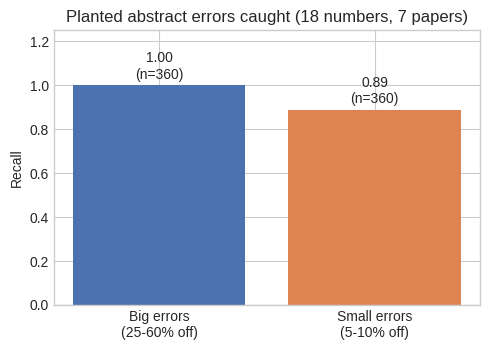

In [10]:
import numcheck
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

def large_perturb(value, decimals, rng):
    new = round(value * rng.choice([0.6, 0.75, 1.25, 1.4, 1.6]), decimals)
    return new if new != value else round(value + 1, decimals)

def small_perturb(value, decimals, rng):
    new = round(value * rng.choice([0.9, 0.95, 1.05, 1.1]), decimals)
    return new if new != value else round(value + 1, decimals)

def run(perturb_fn, seeds=20):
    numcheck.perturb = perturb_fn
    tp = fn = 0
    missed = {}
    for s in range(seeds):
        m, rows = numcheck.evaluate(papers, trials_per_paper=50, seed=s)
        tp += m["tp"]
        fn += m["fn"]
        for r in rows:
            if not r["detected"]:
                missed[(r["paper"], r["old"], r["new"])] = r["keyword"]
    return tp, fn, missed

n_numbers = sum(len(numcheck.checkable_indices(a, b)) for a, b in papers.values())
n_papers = sum(1 for a, b in papers.values() if numcheck.checkable_indices(a, b))
tp_b, fn_b, miss_b = run(large_perturb)
tp_s, fn_s, miss_s = run(small_perturb)
rec_b = tp_b / (tp_b + fn_b)
rec_s = tp_s / (tp_s + fn_s)
print(f"{n_numbers} checkable abstract numbers from {n_papers} papers, each changed 20 times")
print(f"Big errors:   {tp_b}/{tp_b+fn_b} caught, recall {rec_b:.2f}")
print(f"Small errors: {tp_s}/{tp_s+fn_s} caught, recall {rec_s:.2f}")
print("\nMissed (small errors):")
for k, v in miss_s.items():
    print(k, v)

fig, ax = plt.subplots(figsize=(5, 3.6))
labels = ["Big errors\n(25-60% off)", "Small errors\n(5-10% off)"]
vals = [rec_b, rec_s]
ns = [tp_b + fn_b, tp_s + fn_s]
ax.bar(labels, vals, color=["#4C72B0", "#DD8452"])
for i, (v, n) in enumerate(zip(vals, ns)):
    ax.text(i, v + 0.03, f"{v:.2f}\n(n={n})", ha="center")
ax.set_ylim(0, 1.25)
ax.set_ylabel("Recall")
ax.set_title(f"Planted abstract errors caught ({n_numbers} numbers, {n_papers} papers)")
plt.tight_layout()
plt.savefig("results.png", dpi=200)
plt.show()